# Capital Bikeshare 2019: Members vs Casual Riders (SDI Python Module)

About 861,000 Washington DC bike share rides from 2019, joined with hourly weather and US holidays.

**Business question:** How do casual riders use the bikes differently from members, and what does that mean for turning casual riders into members?

Plan:
1. Exploratory Data Analysis I (first look)
2. Cleaning
3. Exploratory Data Analysis II (KPIs)
4. Visualization
5. Recommendations

In [21]:
# Some questions we may answer
# Locationwise customer footprint
# Which days of the week/time of the day/month have the most rides?
# Which bike stations have the most rides?
# Average duration of bike rides
# casual/member breakdown and their bike use?
# Duration wrt member type
# impact of weather conditions

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# chart colors: one fixed color per rider type, used in every chart
COLORS = {'Member': '#2a78d6', 'Casual': '#eb6834'}

In [26]:
df = pd.read_csv('/content/Bikeshare Data.csv')
df.tail()

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,Duration,Start date,End date,Start station number,Start station,End station number,End station,Member type,time,temperature_2m,relativehumidity_2m,precipitation,windspeed_10m,date,holiday,isHoliday
860919,860919,17215693,17215693,933,2019-12-31 13:00:00,2019-12-31 14:00:00,31118.0,3rd & Elm St NW,31243.0,4th & C St SW,Member,2019-12-31 13:00:00,6.2,94,0.0,6.1,2019-12-31,NaN,0
860920,860920,17218561,17218561,593,2019-12-31 21:00:00,2019-12-31 21:00:00,31656.0,Maryland Ave & 17th St NE,31603.0,1st & M St NE,Member,2019-12-31 21:00:00,10.7,45,0.0,10.2,2019-12-31,NaN,0
860921,860921,17213295,17213295,545,2019-12-31 07:00:00,2019-12-31 07:00:00,31506.0,1st & Rhode Island Ave NW,31119.0,14th & Belmont St NW,Member,2019-12-31 07:00:00,6.7,92,0.0,5.2,2019-12-31,NaN,0
860922,860922,17218538,17218538,388,2019-12-31 21:00:00,2019-12-31 21:00:00,31040.0,GMU / Fairfax Dr & Kenmore St,31035.0,N Quincy St & Glebe Rd,Casual,2019-12-31 21:00:00,10.7,45,0.0,10.2,2019-12-31,NaN,0
860923,860923,17213081,17213081,1878,2019-12-31 04:00:00,2019-12-31 05:00:00,31637.0,North Capitol St & G Pl NE,31518.0,New York Ave & Hecht Ave NE,Casual,2019-12-31 04:00:00,7.8,97,0.0,11.8,2019-12-31,NaN,0


## 1. Exploratory Data Analysis I

In [27]:
# number of rows & cols
df.shape

(860924, 19)

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 860924 entries, 0 to 860923
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Unnamed: 0.2          860924 non-null  int64  
 1   Unnamed: 0.1          860924 non-null  int64  
 2   Unnamed: 0            860924 non-null  int64  
 3   Duration              860924 non-null  int64  
 4   Start date            860924 non-null  object 
 5   End date              860924 non-null  object 
 6   Start station number  860924 non-null  float64
 7   Start station         860924 non-null  object 
 8   End station number    860924 non-null  float64
 9   End station           860924 non-null  object 
 10  Member type           860924 non-null  object 
 11  time                  860924 non-null  object 
 12  temperature_2m        860924 non-null  float64
 13  relativehumidity_2m   860924 non-null  int64  
 14  precipitation         860924 non-null  float64
 15  

In [29]:
df.describe()

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,Duration,Start station number,End station number,temperature_2m,relativehumidity_2m,precipitation,windspeed_10m,isHoliday
count,860924.000000,8.609240e+05,8.609240e+05,860924.000000,860924.000000,860924.000000,860924.000000,860924.000000,860924.000000,860924.000000,860924.000000
mean,430461.500000,8.609388e+06,8.609388e+06,1120.725674,31319.361017,31319.903117,17.405877,67.262539,0.094176,9.927104,0.026319
std,248527.495915,4.970667e+06,4.970668e+06,2188.043696,254.176875,273.596149,9.456243,19.859662,0.463163,5.175084,0.160083
min,0.000000,3.000000e+00,3.000000e+00,60.000000,0.000000,0.000000,-19.400000,18.000000,0.000000,0.000000,0.000000
25%,215230.750000,4.304762e+06,4.304762e+06,403.000000,31203.000000,31209.000000,10.500000,50.000000,0.000000,6.300000,0.000000
50%,430461.500000,8.609381e+06,8.609381e+06,692.000000,31254.000000,31251.000000,19.100000,67.000000,0.000000,9.100000,0.000000
75%,645692.250000,1.291397e+07,1.291397e+07,1183.000000,31503.000000,31503.000000,24.600000,85.000000,0.000000,12.600000,0.000000
max,860923.000000,1.721874e+07,1.721874e+07,86305.000000,32609.000000,32609.000000,37.500000,100.000000,17.700000,45.100000,1.000000


In [30]:
# breakdown of members vs casual riders (%)
df['Member type'].value_counts(normalize=True) * 100

,proportion
Member type,
Member,79.142991
Casual,20.857009


In [31]:
# Duration is in seconds
print('Min duration (s):', df['Duration'].min())
print('Max duration (s):', df['Duration'].max())
print('Unique start stations:', df['Start station'].nunique())
print('Unique end stations:', df['End station'].nunique())

Min duration (s): 60
Max duration (s): 86305
Unique start stations: 662
Unique end stations: 660


In [32]:
# data quality issues spotted in the first look:
# - 3 leftover index columns (Unnamed: 0, 0.1, 0.2)
# - station number minimum is 0, which is not a real station
# - max duration is 86,305 seconds (about 24 hours), likely bikes that were never docked
# - holiday is blank on normal days
# - dates are stored as text
print('Rows with station number 0:', ((df['Start station number'] == 0) | (df['End station number'] == 0)).sum())
print('Rides over 3 hours:', (df['Duration'] > 3 * 60 * 60).sum())

Rows with station number 0: 38
Rides over 3 hours: 4140


## 2. Cleaning

In [33]:
rows_start = len(df)

# drop the 3 leftover index columns
df = df.drop(columns=['Unnamed: 0.2', 'Unnamed: 0.1', 'Unnamed: 0'])

# convert seconds to minutes
df['Duration (min)'] = df['Duration'] / 60

# change start/end date to datetime
df['Start date'] = pd.to_datetime(df['Start date'])
df['End date'] = pd.to_datetime(df['End date'])

# fill blank holidays
df['holiday'] = df['holiday'].fillna('Not a Holiday')

# isHoliday is 0/1, make it True/False
df['isHoliday'] = df['isHoliday'].astype(bool)

In [34]:
# remove rides with station number 0 (not a real station)
df = df[(df['Start station number'] != 0) & (df['End station number'] != 0)]

# station numbers are whole numbers, not decimals
df['Start station number'] = df['Start station number'].astype(int)
df['End station number'] = df['End station number'].astype(int)

In [35]:
# Decision: remove rides longer than 3 hours.
# A normal trip is minutes long; rides of up to 24 hours are most likely bikes that were not docked,
# and they would pull the casual average up. Print the count so the decision is documented.
long_rides = df['Duration (min)'] > 180
print('Rides removed (over 3 hours):', long_rides.sum())
df = df[~long_rides]

Rides removed (over 3 hours): 4140


In [36]:
# check & delete duplicates
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates()

print('Rows before cleaning:', rows_start)
print('Rows after cleaning:', len(df))
print('Rows removed:', rows_start - len(df))

Duplicate rows: 129
Rows before cleaning: 860924
Rows after cleaning: 856617
Rows removed: 4307


In [37]:
# helper columns for time analysis
# note: start times are rounded to the hour in this dataset, so hour of day is the finest level we can use
df['Hour'] = df['Start date'].dt.hour
df['Day of week'] = df['Start date'].dt.day_name()
df['Month'] = df['Start date'].dt.month_name()
df['Weekend'] = df['Start date'].dt.dayofweek >= 5
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 856617 entries, 0 to 860923
Data columns (total 21 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   Duration              856617 non-null  int64         
 1   Start date            856617 non-null  datetime64[ns]
 2   End date              856617 non-null  datetime64[ns]
 3   Start station number  856617 non-null  int64         
 4   Start station         856617 non-null  object        
 5   End station number    856617 non-null  int64         
 6   End station           856617 non-null  object        
 7   Member type           856617 non-null  object        
 8   time                  856617 non-null  object        
 9   temperature_2m        856617 non-null  float64       
 10  relativehumidity_2m   856617 non-null  int64         
 11  precipitation         856617 non-null  float64       
 12  windspeed_10m         856617 non-null  float64       
 13  date

## 3. Exploratory Data Analysis II: KPIs

In [38]:
# KPI 1: share of rides by rider type
share = df['Member type'].value_counts(normalize=True) * 100
share.round(1)

,proportion
Member type,
Member,79.4
Casual,20.6


In [39]:
# KPI 2: average and median ride length (minutes)
# median is shown too because ride lengths are skewed by a few long rides
df.groupby('Member type')['Duration (min)'].agg(['mean', 'median']).round(1)

,mean,median
Member type,,
Casual,35.1,24.4
Member,12.3,9.8


In [40]:
# KPI 3: weekend share of rides for each rider type (%)
(df.groupby('Member type')['Weekend'].mean() * 100).round(1)

,Weekend
Member type,
Casual,44.5
Member,21.9


In [41]:
# KPI 4: average temperature (°C) during rides
df.groupby('Member type')['temperature_2m'].mean().round(1)

,temperature_2m
Member type,
Casual,19.4
Member,16.9


In [42]:
# top 10 start stations for casual riders (where to market memberships)
df[df['Member type'] == 'Casual']['Start station'].value_counts().head(10)

,count
Start station,
Lincoln Memorial,10292
Jefferson Dr & 14th St SW,8752
Smithsonian-National Mall / Jefferson Dr & 12th St SW,5834
Jefferson Memorial,4995
Henry Bacon Dr & Lincoln Memorial Circle NW,4863
4th St & Madison Dr NW,4105
17th St & Independence Ave SW,3372
Constitution Ave & 2nd St NW/DOL,3117
4th & C St SW,3007


In [43]:
# top 10 start stations for members
df[df['Member type'] == 'Member']['Start station'].value_counts().head(10)

,count
Start station,
Columbus Circle / Union Station,14549
15th & P St NW,9256
Massachusetts Ave & Dupont Circle NW,9008
New Hampshire Ave & T St NW,7975
14th & V St NW,7139
Thomas Circle,6985
Eastern Market Metro / Pennsylvania Ave & 7th St SE,6887
1st & M St NE,6643
17th & Corcoran St NW,6143


## 4. Visualization

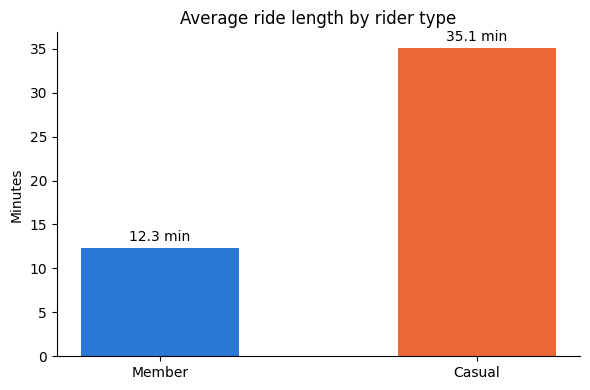

In [44]:
# Chart 1: average ride length by rider type
avg = df.groupby('Member type')['Duration (min)'].mean().reindex(['Member', 'Casual'])

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(avg.index, avg.values, color=[COLORS[t] for t in avg.index], width=0.5)
ax.bar_label(bars, fmt='%.1f min', padding=3)
ax.set_title('Average ride length by rider type')
ax.set_ylabel('Minutes')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

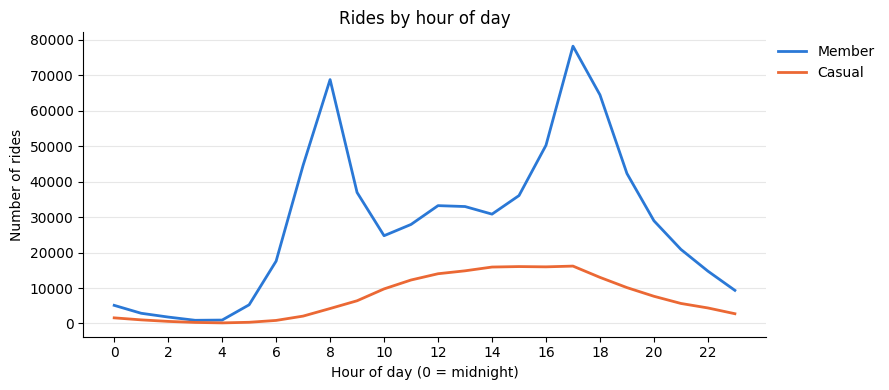

In [45]:
# Chart 2: rides by hour of day (commute peaks vs leisure)
by_hour = df.groupby(['Hour', 'Member type']).size().unstack()

fig, ax = plt.subplots(figsize=(9, 4))
for t in ['Member', 'Casual']:
    ax.plot(by_hour.index, by_hour[t], color=COLORS[t], linewidth=2, label=t)
ax.set_title('Rides by hour of day')
ax.set_xlabel('Hour of day (0 = midnight)')
ax.set_ylabel('Number of rides')
ax.set_xticks(range(0, 24, 2))
ax.grid(axis='y', alpha=0.3)
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

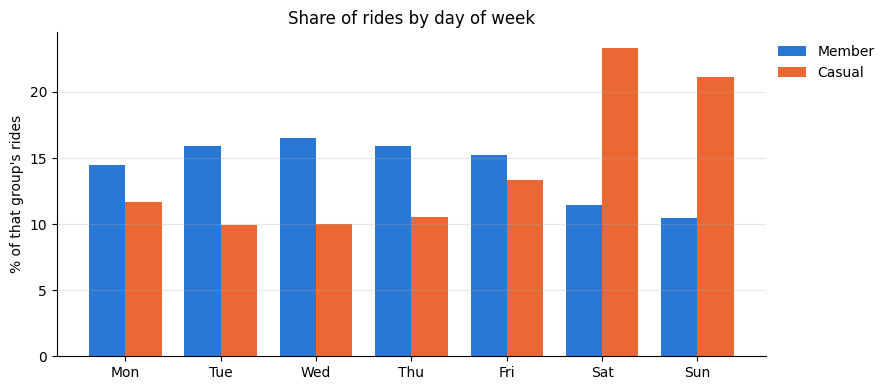

In [46]:
# Chart 3: share of each group's rides by day of week (%), so the two groups are comparable
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
by_day = df.groupby(['Member type', 'Day of week']).size().unstack(0)
by_day = (by_day / by_day.sum() * 100).reindex(days)

fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(days))
w = 0.38
ax.bar([i - w/2 for i in x], by_day['Member'], width=w, color=COLORS['Member'], label='Member')
ax.bar([i + w/2 for i in x], by_day['Casual'], width=w, color=COLORS['Casual'], label='Casual')
ax.set_xticks(list(x))
ax.set_xticklabels([d[:3] for d in days])
ax.set_title('Share of rides by day of week')
ax.set_ylabel('% of that group\'s rides')
ax.grid(axis='y', alpha=0.3)
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

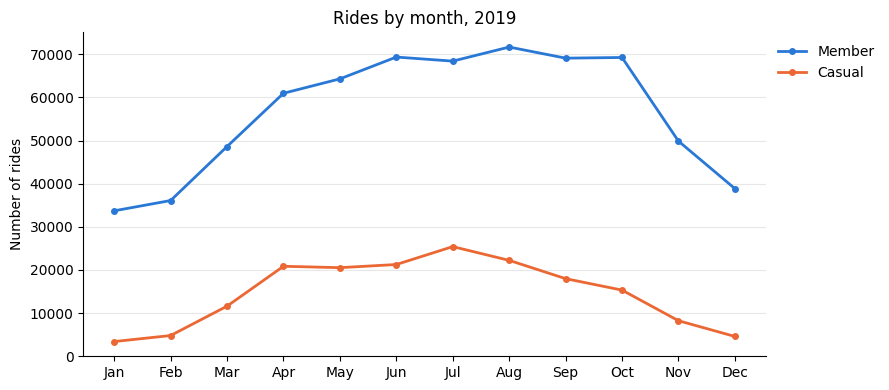

In [47]:
# Chart 4: rides by month (seasonality)
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
          'August', 'September', 'October', 'November', 'December']
by_month = df.groupby(['Month', 'Member type']).size().unstack().reindex(months)

fig, ax = plt.subplots(figsize=(9, 4))
for t in ['Member', 'Casual']:
    ax.plot([m[:3] for m in months], by_month[t], color=COLORS[t], linewidth=2, marker='o', markersize=4, label=t)
ax.set_title('Rides by month, 2019')
ax.set_ylabel('Number of rides')
ax.grid(axis='y', alpha=0.3)
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 5. Recommendations / Final thoughts

In [48]:
# summary of the KPIs behind the recommendations
summary = pd.DataFrame({
    'Share of rides (%)': share.round(1),
    'Avg ride (min)': df.groupby('Member type')['Duration (min)'].mean().round(1),
    'Weekend rides (%)': (df.groupby('Member type')['Weekend'].mean() * 100).round(1),
    'Avg temp (°C)': df.groupby('Member type')['temperature_2m'].mean().round(1),
})
summary

,Share of rides (%),Avg ride (min),Weekend rides (%),Avg temp (°C)
Member type,,,,
Casual,20.6,35.1,44.5,19.4
Member,79.4,12.3,21.9,16.9


**What the data shows** (856,617 rides after cleaning):

- **Members are commuters.** They take 79.4% of all rides, with short trips (12.3 minutes on average, 9.8 median). Their rides spike at 8 AM and 5 PM, and their top start stations are transit and neighborhood hubs like Union Station and Dupont Circle.
- **Casual riders are leisure riders, and many look like visitors.** Their rides are almost 3 times longer (35.1 minutes on average, 24.4 median), 44.5% of them happen on weekends (vs 21.9% for members), and they ride in warmer weather (19.4°C vs 16.9°C). Their riding builds through the afternoon instead of spiking at rush hour. Their top 10 start stations are almost all on the National Mall: Lincoln Memorial, Jefferson Memorial, the Smithsonian.
- **Casual riding is very seasonal.** It jumps in April, peaks in July, and drops to a fraction of that in winter.

**Recommendations:**

1. **Don't treat all casual riders as future annual members.** Many are tourists on the National Mall. Offer them better day passes or multi-day visitor passes instead.
2. **Target local casual riders for membership**, the ones starting outside the Mall stations, with a weekend or seasonal membership that matches how they actually ride.
3. **Run membership campaigns from March to July**, before and during the casual peak, and put the Mall stations' offers in front of riders where they already are.

**Limitations:**

- Start times are rounded to the hour, so trip times can't be checked to the minute.
- 4,140 rides over 3 hours were removed as likely undocked bikes. This was a judgment call, documented above.
- The data has no rider IDs, so I can't tell which casual riders are tourists and which are locals. The station pattern suggests it, but doesn't prove it.
- The data covers 2019 only, so the patterns may have changed since.